# 01 Catalog exploration

Load the California ComCat catalog, check completeness and the b-value, and look at clustering. Run `uv run quakecast fetch --start 2018-01-01 --min-mag 3.0` first.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from quakecast import catalog, etas

df = catalog.load("../data/california_comcat.parquet")
print(len(df), df["time"].min(), df["time"].max())
df.tail()

4956 2018-01-01 01:35:34.240000+00:00 2026-10-23 05:38:19.230000+00:00


,time,lat,lon,depth_km,mag
4951,2026-10-21 15:55:24.610+00:00,40.883499,-120.606163,6.23,3.13
4952,2026-10-22 01:43:10.400+00:00,40.234501,-124.170830,10.99,3.25
4953,2026-10-22 04:18:34.430+00:00,37.169998,-121.229668,-0.70,3.15
4954,2026-10-22 21:58:44.270+00:00,36.656334,-121.301498,5.57,3.03
4955,2026-10-23 05:38:19.230+00:00,40.617832,-125.093834,10.36,3.37


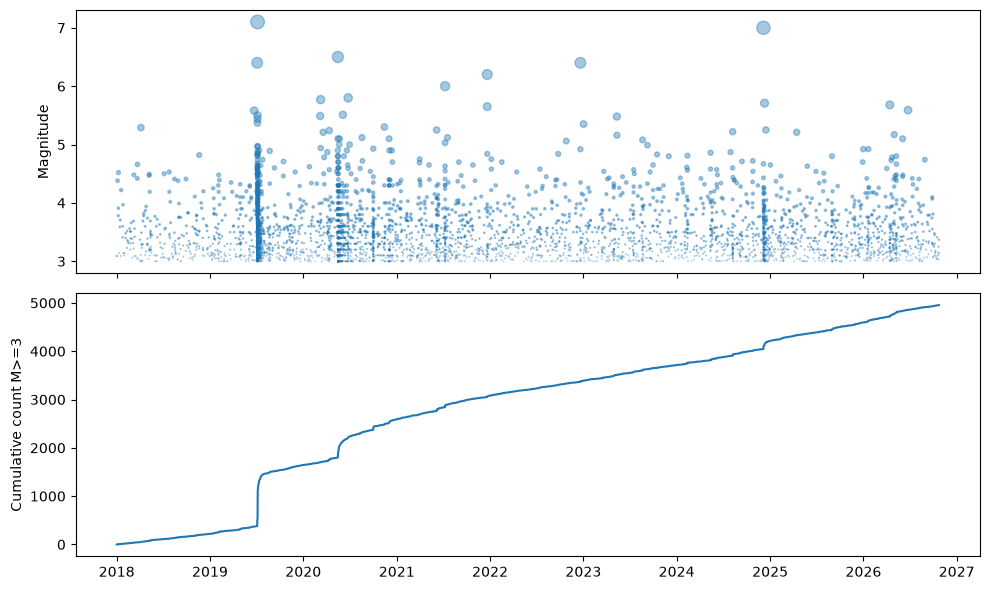

In [2]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].scatter(df["time"], df["mag"], s=(df["mag"] - 2.5) ** 3, alpha=0.4)
ax[0].set_ylabel("Magnitude")
ax[1].plot(df["time"], np.arange(len(df)))
ax[1].set_ylabel("Cumulative count M>=3")
plt.tight_layout()

Steps in the cumulative count are aftershock sequences. That clustering is what ETAS captures and what a Poisson model misses.

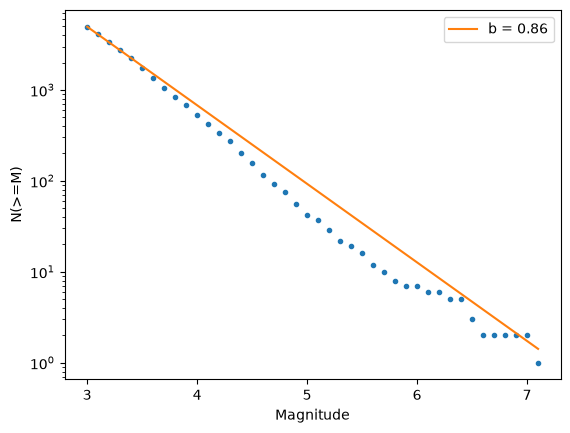

In [3]:
bins = np.arange(3.0, df["mag"].max() + 0.1, 0.1)
counts = np.array([(df["mag"] >= m - 1e-9).sum() for m in bins])
b = etas.b_value(df["mag"].to_numpy(), 3.0)
plt.semilogy(bins, counts, "o", ms=3)
plt.semilogy(bins, counts[0] * 10 ** (-b * (bins - 3.0)), label=f"b = {b:.2f}")
plt.xlabel("Magnitude")
plt.ylabel("N(>=M)")
plt.legend();

A straight line from M3 means the catalog is complete at M3. If the low end bends down, raise `m0`.